In [1]:
import math
import torch
import matplotlib.pyplot as plt

from freqsde import VEConvMixSDE   # adjust to your filename

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)

device: cuda


In [2]:
K     = 2
N_fft = 10
T     = 1.0
N     = 100
alpha = 1.
beta  = 1.

sde = VEConvMixSDE(
    ndim      = K * N_fft,
    alpha     = alpha,
    beta      = beta,
    sigma_min = 0.1,
    sigma_max = 0.2,
    steps     = 10000,
    T         = T,
    N         = N,
)

torch.manual_seed(0)
kernels = torch.randn(K, N_fft, dtype=torch.complex64) + 1.0

sde.get_mix_mat(kernels, N_fft)
sde.send_to(DEVICE)

In [3]:
t = torch.tensor([1]).to(DEVICE)
Ft = sde.get_Ft(t)
Ft.shape

torch.Size([1, 20, 20])

In [4]:
import numpy as np
sigma_t = sde.sigma_min * (sde.ratiosig ** (t / sde.T))  # (B,)
diff = sigma_t * np.sqrt(
    2 * sde.logsig
)  # (B, ) diffusion sacalr the matrix Dt (Paper) is g(t)*I

Bt = diff[:, None, None] * sde.eigvecs

In [5]:
Bt.shape

torch.Size([1, 20, 20])

In [6]:
import numpy as np

def discretize_lyapunov(t_start, t_end, dt):
    """
    """
    t = t_start
    Sigma = Sigma_0

    while t < t_end:
        
        Ft = sde.get_Ft(torch.tensor([t]).to(DEVICE))[0]
        sigma_t = sde.sigma_min * (sde.ratiosig ** (torch.tensor([t]).to(DEVICE) / sde.T))  # (B,)
        diff = sigma_t * np.sqrt(
            2 * sde.logsig
        )  # (B, ) diffusion sacalr the matrix Dt (Paper) is g(t)*I

        Bt = diff[:, None, None] * sde.eigvecs
        BBH = Bt[0] @ Bt[0].conj().T
        dSigma = Ft @ Sigma + Sigma @ Ft.conj().T + BBH
        Sigma = Sigma + dt * dSigma
        t += dt
    return Sigma




Sigma_0 = torch.eye(N_fft * K, dtype=torch.complex64, device=DEVICE)  * 0

t_start = 0.0
t_end   = 1.
dt      = 1e-4

Sigma_final = discretize_lyapunov(t_start, t_end, dt)

print(f"Sigma at t = {t_end}:")
print(np.round(Sigma_final.cpu(), 4))

Sigma at t = 1.0:
tensor([[0.1178+0.0000e+00j, 0.0000+0.0000e+00j, 0.0000+0.0000e+00j,
         0.0000+0.0000e+00j, 0.0000+0.0000e+00j, 0.0000+0.0000e+00j,
         0.0000+0.0000e+00j, 0.0000+0.0000e+00j, 0.0000+0.0000e+00j,
         0.0000+0.0000e+00j, 0.0187-2.1000e-02j, 0.0000+0.0000e+00j,
         0.0000+0.0000e+00j, 0.0000+0.0000e+00j, 0.0000+0.0000e+00j,
         0.0000+0.0000e+00j, 0.0000+0.0000e+00j, 0.0000+0.0000e+00j,
         0.0000+0.0000e+00j, 0.0000+0.0000e+00j],
        [0.0000+0.0000e+00j, 0.0863+0.0000e+00j, 0.0000+0.0000e+00j,
         0.0000+0.0000e+00j, 0.0000+0.0000e+00j, 0.0000+0.0000e+00j,
         0.0000+0.0000e+00j, 0.0000+0.0000e+00j, 0.0000+0.0000e+00j,
         0.0000+0.0000e+00j, 0.0000+0.0000e+00j, 0.0347-2.6900e-02j,
         0.0000+0.0000e+00j, 0.0000+0.0000e+00j, 0.0000+0.0000e+00j,
         0.0000+0.0000e+00j, 0.0000+0.0000e+00j, 0.0000+0.0000e+00j,
         0.0000+0.0000e+00j, 0.0000+0.0000e+00j],
        [0.0000+0.0000e+00j, 0.0000+0.0000e+00j, 0.050

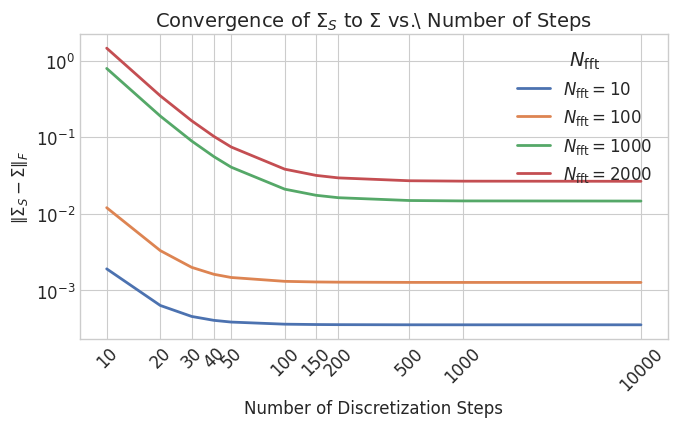

In [9]:
K     = 2
T     = 1.0
N     = 100
alpha = 1.
beta  = 1.

N_fft_list = [10, 100, 1000, 2000]
steps      = [10, 20, 30, 40, 50, 100, 150, 200, 500, 1000, 10000]

STYLE  = "seaborn-v0_8-whitegrid"
COLORS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]

plt.rcParams.update({
    "font.family":       "DejaVu Sans",
    "font.size":         14,
    "axes.titlesize":    14,
    "axes.labelsize":    12,
    "xtick.labelsize":   12,
    "ytick.labelsize":   12,
    "legend.fontsize":   12,
    "lines.linewidth":   2.0,
    "axes.spines.top":   True,
    "axes.spines.right": True,
    "axes.grid":         True,
    "grid.color":        "#e0e0e0",
    "grid.linewidth":    0.8,
    "grid.linestyle":    "--",
    "axes.axisbelow":    True,
})

def discretize_lyapunov(sde, Sigma_0, t_start, t_end, dt):
    t     = t_start
    Sigma = Sigma_0.clone()
    while t < t_end:
        Ft      = sde.get_Ft(torch.tensor([t]).to(DEVICE))[0]
        sigma_t = sde.sigma_min * (sde.ratiosig ** (torch.tensor([t]).to(DEVICE) / sde.T))
        diff    = sigma_t * np.sqrt(2 * sde.logsig)
        Bt      = diff[:, None, None] * sde.eigvecs
        BBH     = Bt[0] @ Bt[0].conj().T
        dSigma  = Ft @ Sigma + Sigma @ Ft.conj().T + BBH
        Sigma   = Sigma + dt * dSigma
        t      += dt
    return Sigma

with plt.style.context(STYLE):
    fig, ax = plt.subplots(figsize=(7, 4.5))

    for N_fft, color in zip(N_fft_list, COLORS):

        # ── build SDE ────────────────────────────────────────────────────────
        sde = VEConvMixSDE(
            ndim      = K * N_fft,
            alpha     = alpha,
            beta      = beta,
            sigma_min = 0.1,
            sigma_max = 0.2,
            steps     = 10000,
            T         = T,
            N         = N,
        )
        torch.manual_seed(0)
        kernels = torch.randn(K, N_fft, dtype=torch.complex64) + 1.0
        sde.get_mix_mat(kernels, N_fft)
        sde.send_to(DEVICE)

        # ── reference covariance via Lyapunov discretization ─────────────────
        Sigma_0     = torch.zeros(N_fft * K, N_fft * K, dtype=torch.complex64, device=DEVICE)
        Sigma_final = discretize_lyapunov(sde, Sigma_0, t_start=0.0, t_end=1.0, dt=1e-3)

        # ── compute distances ─────────────────────────────────────────────────
        distances = []
        for step in steps:
            sde.steps = step
            S      = sde.eigvecs @ torch.diag_embed(
                sde._std(torch.tensor([1.0], dtype=torch.complex64).to(DEVICE))
            )
            SigmaS = S[0] @ S[0].conj().T
            dist   = torch.norm(SigmaS - Sigma_final, p='fro').real.item()
            distances.append(dist)

        ax.plot(
            steps, distances,
            color=color,
            linewidth=2.0,
            label=rf"$N_{{\mathrm{{fft}}}} = {N_fft}$",
        )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Number of Discretization Steps")
    ax.set_ylabel(r"$\left\|\Sigma_S - \Sigma\right\|_F$")
    ax.set_title(r"Convergence of $\Sigma_S$ to $\Sigma$ vs.\ Number of Steps")
    ax.set_xticks(steps)
    ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.tick_params(axis='x', rotation=45)
    ax.legend(framealpha=0.9, title=r"$N_{\mathrm{fft}}$")

    fig.tight_layout()
    plt.show()

In [ ]:
import matplotlib.lines as mlines
import matplotlib.pyplot as plt

import numpy as np
import torch
from matplotlib.ticker import LogLocator, LogFormatter, ScalarFormatter

K     = 2
T     = 1.0
N     = 100
alpha = 1.
beta  = 1.

N_fft_list = [10, 100, 500, 1000]
steps      = [10, 50, 100, 150, 200, 500, 1000, 10000]

STYLE   = "seaborn-v0_8-whitegrid"
COLORS  = ["#4C72B0", "#DD8452", "#55A868", "#C44E52" ]
STYLES  = ["-", "--"]

METRICS = [
    (r"$\|\Sigma_S - \Sigma\|_F$",            "Frobenius"),
    (r"$\mathrm{mean}(|\Sigma_S - \Sigma|)$", "Mean Abs"),
]

plt.rcParams.update({
    "font.family":           "DejaVu Sans",
    "font.size":             13,
    "axes.titlesize":        13,
    "axes.labelsize":        12,
    "xtick.labelsize":       11,
    "ytick.labelsize":       11,
    "legend.fontsize":       10,
    "legend.title_fontsize": 11,
    "lines.linewidth":       2.0,
    "axes.spines.top":       False,
    "axes.spines.right":     False,
    "axes.grid":             True,
    "axes.grid.which":       "both",
    "grid.color":            "#e0e0e0",
    "grid.linewidth":        0.8,
    "grid.linestyle":        "--",
    "axes.axisbelow":        True,
    "figure.dpi":            150,
})

def discretize_lyapunov(sde, Sigma_0, t_start, t_end, dt):
    t     = t_start
    Sigma = Sigma_0.clone()
    while t < t_end:
        Ft      = sde.get_Ft(torch.tensor([t]).to(DEVICE))[0]
        sigma_t = sde.sigma_min * (sde.ratiosig ** (torch.tensor([t]).to(DEVICE) / sde.T))
        diff    = sigma_t * np.sqrt(2 * sde.logsig)
        Bt      = diff[:, None, None] * sde.eigvecs
        BBH     = Bt[0] @ Bt[0].conj().T
        dSigma  = Ft @ Sigma + Sigma @ Ft.conj().T + BBH
        Sigma   = Sigma + dt * dSigma
        t      += dt
    return Sigma

In [ ]:
import time

# ── compute ───────────────────────────────────────────────────────────────────
all_distances = {n: {"fro": [], "mean": []} for n in N_fft_list}
time_lyap     = {}
time_sde      = {}

for N_fft in N_fft_list:
    sde = VEConvMixSDE(
        ndim      = K * N_fft,
        alpha     = alpha,
        beta      = beta,
        sigma_min = 0.1,
        sigma_max = 0.2,
        steps     = 10000,
        T         = T,
        N         = N,
    )
    torch.manual_seed(0)
    kernels = torch.randn(K, N_fft, dtype=torch.complex64) + 1.0
    sde.get_mix_mat(kernels, N_fft)
    sde.send_to(DEVICE)

    # ── reference covariance ─────────────────────────────────────────────────
    Sigma_0 = torch.zeros(N_fft * K, N_fft * K, dtype=torch.complex64, device=DEVICE)
    t0 = time.perf_counter()
    Sigma_final = discretize_lyapunov(sde, Sigma_0, t_start=0.0, t_end=1.0, dt=1e-4)
    time_lyap[N_fft] = time.perf_counter() - t0

    # ── analytic SigmaS at max steps ─────────────────────────────────────────
    sde.steps = steps[-1]
    t0 = time.perf_counter()
    S  = sde.eigvecs @ torch.diag_embed(
        sde._std(torch.tensor([1.0], dtype=torch.complex64).to(DEVICE))
    )
    _ = S[0] @ S[0].conj().T
    time_sde[N_fft] = time.perf_counter() - t0

    # ── distances across all steps ────────────────────────────────────────────
    for step in steps:
        sde.steps = step
        S      = sde.eigvecs @ torch.diag_embed(
            sde._std(torch.tensor([1.0], dtype=torch.complex64).to(DEVICE))
        )
        SigmaS = S[0] @ S[0].conj().T
        diff   = SigmaS - Sigma_final

        all_distances[N_fft]["fro"].append(torch.norm(diff, p='fro').real.item())
        all_distances[N_fft]["mean"].append(diff.abs().mean().item())
        #all_distances[N_fft]["max"].append(diff.abs().max().item())



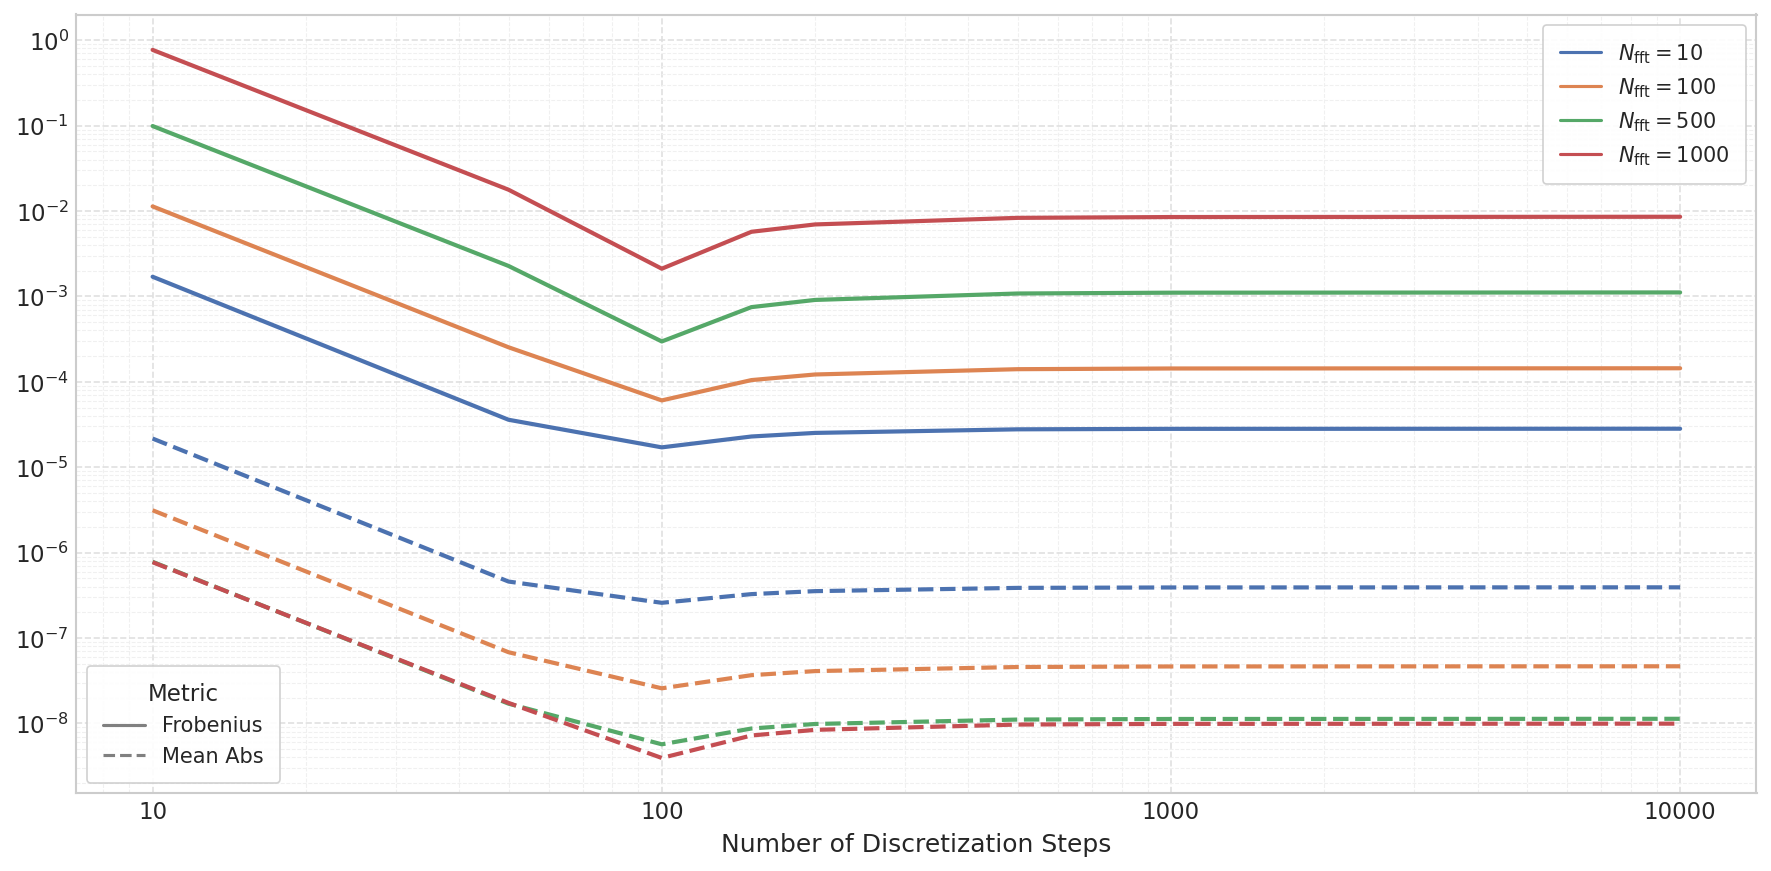

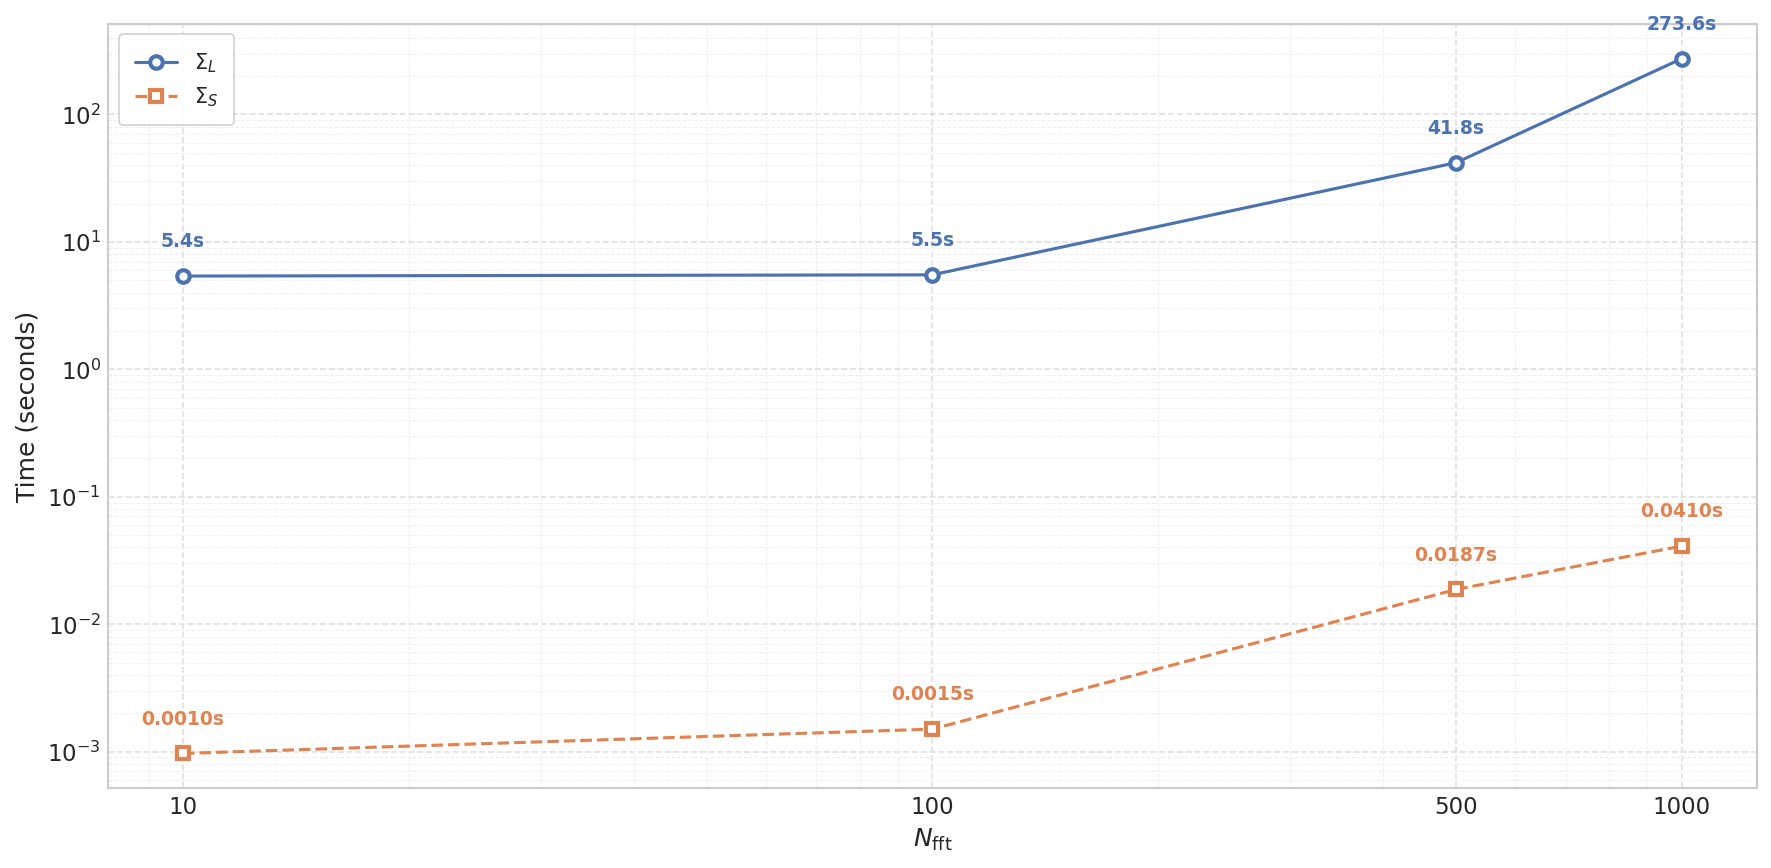

In [57]:
# ── plot ──────────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "font.family":           "DejaVu Sans",
    "font.size":             13,
    "axes.titlesize":        13,
    "axes.labelsize":        12,
    "xtick.labelsize":       11,
    "ytick.labelsize":       11,
    "legend.fontsize":       10,
    "legend.title_fontsize": 11,
    "legend.frameon":        True,
    "legend.framealpha":     1.0,
    "legend.edgecolor":      "#aaaaaa",
    "legend.facecolor":      "white",
    "lines.linewidth":       2.0,
    "axes.spines.top":   True,
    "axes.spines.right": True,
    "axes.grid":             True,
    "axes.grid.which":       "both",
    "grid.color":            "#e0e0e0",
    "grid.linewidth":        0.8,
    "grid.linestyle":        "--",
    "axes.axisbelow":        True,
    "figure.dpi":            150,
})

# ── figure 1: convergence ─────────────────────────────────────────────────────
with plt.style.context(STYLE):
    fig1, ax_conv = plt.subplots(figsize=(12, 6))

    for N_fft, color in zip(N_fft_list, COLORS):
        d = all_distances[N_fft]
        for (_, metric_label), ls, dist_list in zip(
            METRICS, STYLES,
            [d["fro"], d["mean"]]
        ):
            ax_conv.plot(
                steps, dist_list,
                color=color, linestyle=ls, linewidth=2.0,
            )

    ax_conv.set_xscale("log")
    ax_conv.set_yscale("log")
    ax_conv.set_xlabel("Number of Discretization Steps")
    ax_conv.xaxis.set_major_locator(LogLocator(base=10, numticks=10))
    ax_conv.xaxis.set_minor_locator(LogLocator(base=10, subs='auto', numticks=50))
    ax_conv.xaxis.set_major_formatter(LogFormatter(base=10, labelOnlyBase=True))
    ax_conv.yaxis.set_major_locator(LogLocator(base=10, numticks=10))
    ax_conv.yaxis.set_minor_locator(LogLocator(base=10, subs='auto', numticks=50))
    ax_conv.grid(which='minor', color='#f0f0f0', linewidth=0.5, linestyle='--')
    ax_conv.grid(which='major', color='#e0e0e0', linewidth=0.8, linestyle='--')


    color_handles = [
        mlines.Line2D([], [], color=c, linewidth=1.5,
                      label=rf"$N_{{\mathrm{{fft}}}}={n}$")
        for c, n in zip(COLORS, N_fft_list)
    ]
    style_handles = [
        mlines.Line2D([], [], color="grey", linestyle=ls, linewidth=1.5,
                      label=lbl)
        for (_, lbl), ls in zip(METRICS, STYLES)
    ]

    leg1 = ax_conv.legend(
        handles=color_handles,
        loc="upper right",
        frameon=True, framealpha=0.9,
        edgecolor="#cccccc", fancybox=True,
        borderpad=0.8, labelspacing=0.5,
        facecolor="white", fontsize=10,
    )
    leg1.get_frame().set_linewidth(0.8)
    ax_conv.add_artist(leg1)

    leg2 = ax_conv.legend(
        handles=style_handles,
        title="Metric",
        loc="lower left",
        frameon=True, framealpha=0.9,
        edgecolor="#cccccc", fancybox=True,
        borderpad=0.8, labelspacing=0.5,
        facecolor="white", fontsize=10,
    )
    leg2.get_frame().set_linewidth(0.8)

    fig1.tight_layout()
    plt.savefig("sigma_convergence.pdf", bbox_inches="tight", dpi=300)
    plt.show()

# ── figure 2: timing ──────────────────────────────────────────────────────────
with plt.style.context(STYLE):
    fig2, ax_time = plt.subplots(figsize=(12, 6))

    lyap_times = [time_lyap[n] for n in N_fft_list]
    sde_times  = [time_sde[n]  for n in N_fft_list]

    ax_time.plot(
        N_fft_list, lyap_times,
        color="#4C72B0", linestyle="-", linewidth=1.5,
        marker="o", markersize=6, markerfacecolor="white",
        markeredgewidth=2, label=r"$\Sigma_L$ ",
    )
    ax_time.plot(
        N_fft_list, sde_times,
        color="#DD8452", linestyle="--", linewidth=1.5,
        marker="s", markersize=6, markerfacecolor="white",
        markeredgewidth=2, label=rf"$\Sigma_S$",
    )

    for n, tl, ts in zip(N_fft_list, lyap_times, sde_times):
        ax_time.annotate(
            f"{tl:.1f}s", xy=(n, tl),
            xytext=(0, 12), textcoords="offset points",
            ha='center', va='bottom', fontsize=9,
            color="#4C72B0", fontweight='bold',
        )
        ax_time.annotate(
            f"{ts:.4f}s", xy=(n, ts),
            xytext=(0, 12), textcoords="offset points",
            ha='center', va='bottom', fontsize=9,
            color="#DD8452", fontweight='bold',
        )


    ax_time.set_xscale("log")
    ax_time.set_yscale("log")
    ax_time.set_xlabel(r"$N_{\mathrm{fft}}$")
    ax_time.set_ylabel("Time (seconds)")
    ax_time.set_xticks(N_fft_list)
    ax_time.get_xaxis().set_major_formatter(ScalarFormatter())
    ax_time.xaxis.set_minor_locator(LogLocator(base=10, subs='auto', numticks=50))
    ax_time.yaxis.set_major_locator(LogLocator(base=10, numticks=10))
    ax_time.yaxis.set_minor_locator(LogLocator(base=10, subs='auto', numticks=50))
    ax_time.grid(which='minor', color='#f0f0f0', linewidth=0.5, linestyle='--')
    ax_time.grid(which='major', color='#e0e0e0', linewidth=0.8, linestyle='--')

    ax.set_axisbelow(True)
    leg3 = ax_time.legend(
        loc="upper left",
        frameon=True, framealpha=0.9,
        edgecolor="#cccccc", fancybox=True,
        borderpad=0.8, labelspacing=0.5,
        facecolor="white", fontsize=10,
    )
    leg3.get_frame().set_linewidth(0.8)

    fig2.tight_layout()
    plt.savefig("sigma_timing.pdf", bbox_inches="tight", dpi=300)
    plt.show()